# 08 · Acciones variables: masking y pointer attention
**Entornos:** MiniDespacho (mediano, grande) y MiniCartas · **Tiempo de ejecución:** ≤ 8 min en CPU · **Criterio de la lección:** el enmascarado nunca elige una opción ilegal; un pointer entrenado con PPO
iguala a `GreedyDespacho` en "mediano", transfiere sin reentrenar a "grande" y le gana ≥ 70 % al aleatorio en MiniCartas.

## 1. La idea en una frase
Cuando las opciones legales cambian en cada paso hay dos formas de puntuarlas: una **máscara** sobre ids de acción fijos, o **pointer attention**, que puntúa cada opción a partir de *sus propias features*.

**En el sistema de Luca:** la query sale del token global, las keys de los tokens de opción, se enmascaran las ilegales y se aplica softmax: pointer attention.
**En un problema de negocio:** el conjunto de (pedido, camión) posibles cambia con cada llegada; puntuar cada par por sus features (distancia, holgura, capacidad) generaliza a flotas de otro tamaño.

## 2. La intuición y la fórmula
- **Máscara:** la red da un logit por cada id global de acción y se ponen a $-\infty$ los ilegales antes del softmax, así $\pi(\text{ilegal}) = 0$ **exactamente**.
  Limitación: la red tiene tantas salidas como ids, así que está atada a un tamaño de entorno.
- **Pointer:** una query $q = W_q h_{\text{global}}$ y una key $k_j = W_k\,\phi(\text{opción}_j)$ por opción; el logit es

  $$\ell_j = \frac{q \cdot k_j}{\sqrt d}, \qquad \pi(j) = \text{softmax}_j\bigl(\ell_j \text{ con } -\infty \text{ en las ilegales}\bigr).$$

  No hay pesos por id: el mismo modelo puntúa 3 o 73 opciones.

In [1]:
import os
import copy
import numpy as np
import torch
import matplotlib.pyplot as plt
from rlf.core import EVAL_SEED_BASE, VecEnv, BatchObs, to_torch, seed_everything
from rlf.eval.stats import mean_ci, paired_diff_ci, passes_lower
from rlf.eval.arena import evaluate_policy, play_games
from rlf.envs.despacho import DespachoEnv
from rlf.envs.cartas import CartasEnv
from rlf.envs.wrappers import VsOpponent
from rlf.agents.baselines import RandomPolicy, GreedyDespacho
from rlf.agents.policy import ActorCriticPolicy
from rlf.agents.ppo import PPO, PPOConfig
from rlf.nets.mlp import MLPActorCritic
from rlf.nets.pointer import PointerActorCritic
TRAIN_SEED = int(os.environ.get("RLF_TRAIN_SEED", "0"))
seed_everything(TRAIN_SEED)
CPU = torch.device("cpu")
make_med = lambda: DespachoEnv.from_size("mediano")
make_big = lambda: DespachoEnv.from_size("grande")
make_cartas = lambda: CartasEnv()

## 3. El núcleo: el cálculo `query·keys/√d` con máscara
Inline, y una celda lo compara con `PointerActorCritic` de `rlf`.

In [2]:
def pointer_logits(query, keys, option_mask):
    """query [B, d], keys [B, n_opts, d], option_mask [B, n_opts] → logits [B, n_opts] con −∞ en las ilegales."""
    d = query.shape[-1]
    scores = (keys * query.unsqueeze(1)).sum(-1) / d ** 0.5           # producto punto query·key, escalado por √d
    return scores.masked_fill(~option_mask, float("-inf"))            # las opciones ilegales no reciben probabilidad

vec = VecEnv(make_med, 8, seed=1)
obs = vec.reset()
for _ in range(5):
    obs = vec.step(np.zeros(8, dtype=np.int64)).obs
t = to_torch(obs, CPU)
net = PointerActorCritic(make_med().spec, d_model=32)
h = net.encode_global(t)
mine = pointer_logits(net.w_q(h), net.w_k(torch.relu(net.opt(t.options))), t.option_mask)
ref, _ = net(t)
assert torch.equal(torch.isinf(mine), torch.isinf(ref)) and torch.allclose(torch.nan_to_num(mine, neginf=0), torch.nan_to_num(ref, neginf=0), atol=1e-6)
print("pointer inline == PointerActorCritic; opciones legales por observación:", t.option_mask.sum(1).tolist())

pointer inline == PointerActorCritic; opciones legales por observación: [1, 3, 1, 1, 2, 1, 3, 2]


## 4. Entrenar y graficar la curva de aprendizaje
Tres entrenamientos con PPO (lección 7): un pointer en "mediano" (400 000 pasos), un MLP sobre ids en "mediano" (150 000 y 400 000 pasos, para comparar) y un pointer contra `RandomPolicy` en MiniCartas (200 000 pasos).
El de MiniCartas usa `VsOpponent`: un envoltorio que deja jugar al oponente dentro de `step` para que el aprendiz vea un problema de un jugador.

mediano: aleatorio -118.2, greedy -77.5;   grande: aleatorio -1763.0, greedy -1686.3


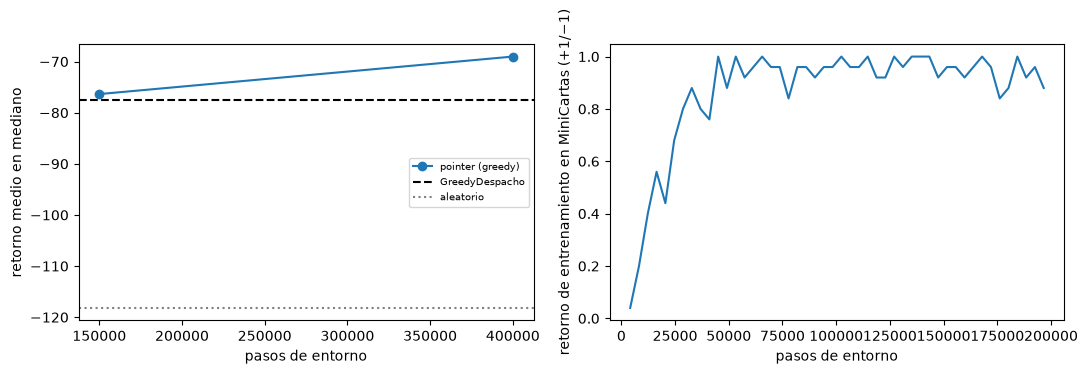

pointer mediano: [(150000, np.float64(-76.4)), (400000, np.float64(-69.0))]


In [3]:
N = 1000
rand_med = evaluate_policy(make_med, RandomPolicy(TRAIN_SEED), N)
greedy_med = evaluate_policy(make_med, GreedyDespacho(), N)
rand_big = evaluate_policy(make_big, RandomPolicy(TRAIN_SEED), N)
greedy_big = evaluate_policy(make_big, GreedyDespacho(), N)
print(f"mediano: aleatorio {rand_med.mean():.1f}, greedy {greedy_med.mean():.1f};   grande: aleatorio {rand_big.mean():.1f}, greedy {greedy_big.mean():.1f}")

def despacho_cfg(): return PPOConfig(gamma=0.97, lam=0.9, lr=1e-3, epochs=10, minibatches=8, reward_scale=1 / 68)

# pointer en mediano, con una foto a los 150 000 pasos para la comparación justa del experimento 2
torch.manual_seed(TRAIN_SEED)
pointer = PointerActorCritic(make_med().spec, d_model=64)
ppo_p = PPO(pointer, despacho_cfg(), seed=TRAIN_SEED)
vec_p = VecEnv(make_med, 64, seed=TRAIN_SEED)
ppo_p.train(vec_p, 150_000)
pointer_150k = copy.deepcopy(pointer)
curve_p = [(150_000, evaluate_policy(make_med, ActorCriticPolicy(pointer, greedy=True), N).mean())]
ppo_p.train(vec_p, 250_000)
curve_p.append((400_000, evaluate_policy(make_med, ActorCriticPolicy(pointer, greedy=True), N).mean()))

# MLP sobre ids, mismo presupuesto que la foto del pointer
torch.manual_seed(TRAIN_SEED)
mlp = MLPActorCritic(make_med().spec, hidden=(128, 128))
ppo_m = PPO(mlp, despacho_cfg(), seed=TRAIN_SEED)
vec_m = VecEnv(make_med, 64, seed=TRAIN_SEED)
ppo_m.train(vec_m, 150_000)
mlp_150k = copy.deepcopy(mlp)
ppo_m.train(vec_m, 250_000)

# pointer en MiniCartas contra el aleatorio
torch.manual_seed(TRAIN_SEED)
pointer_c = PointerActorCritic(make_cartas().spec, d_model=64)
ppo_c = PPO(pointer_c, PPOConfig(gamma=1.0, lam=0.95, lr=1e-3, epochs=6, minibatches=8), seed=TRAIN_SEED)
ppo_c.train(VecEnv(lambda: VsOpponent(make_cartas, RandomPolicy(0)), 64, seed=TRAIN_SEED), 200_000)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot([c[0] for c in curve_p], [c[1] for c in curve_p], marker="o", label="pointer (greedy)")
ax[0].axhline(greedy_med.mean(), color="k", ls="--", label="GreedyDespacho"); ax[0].axhline(rand_med.mean(), color="gray", ls=":", label="aleatorio")
ax[0].set_xlabel("pasos de entorno"); ax[0].set_ylabel("retorno medio en mediano"); ax[0].legend(fontsize=7)
ax[1].plot([h["steps"] for h in ppo_c.history], [h["mean_return"] for h in ppo_c.history])
ax[1].set_xlabel("pasos de entorno"); ax[1].set_ylabel("retorno de entrenamiento en MiniCartas (+1/−1)")
plt.tight_layout(); plt.show()
print("pointer mediano:", [(s, round(r, 1)) for s, r in curve_p])

## 5. Experimentos "predice antes de correr"

### Experimento 1 · ¿Qué pasa sin máscara?
**Predice:** con una red sin entrenar, si hacemos softmax sobre **todas** las posiciones (incluido el relleno), ¿cuánta probabilidad cae en opciones que no existen?

In [4]:
def illegal_mass(net, make_env, steps=30):
    """Probabilidad media sobre posiciones ilegales, con y sin máscara."""
    vec = VecEnv(make_env, 50, seed=5); obs = vec.reset(); rng = np.random.default_rng(0)
    unmasked, masked = [], []
    for _ in range(steps):
        t = to_torch(obs, CPU)
        with torch.no_grad():
            logits, _ = net(t)                                     # con máscara (−∞ en ilegales)
            raw = logits.masked_fill(~t.option_mask, 0.0)           # "sin máscara": las posiciones ilegales valen 0, no −∞
        masked.append(float(torch.softmax(logits, -1)[~t.option_mask].sum(-1).mean() if (~t.option_mask).any() else 0.0))
        unmasked.append(float((torch.softmax(raw, -1) * (~t.option_mask)).sum(-1).mean()))
        obs = vec.step(rng.integers(0, obs.n_options)).obs
    return np.mean(unmasked), np.mean(masked)

torch.manual_seed(TRAIN_SEED)
for name, net_, make in (("pointer, mediano", PointerActorCritic(make_med().spec), make_med),
                         ("pointer, MiniCartas", PointerActorCritic(make_cartas().spec), make_cartas)):
    u, m = illegal_mass(net_, make)
    print(f"{name:22s} probabilidad sobre ilegales: sin máscara {u:.3f}   con máscara {m:.3f}")
    assert u > 0.3 and m == 0.0

pointer, mediano       probabilidad sobre ilegales: sin máscara 0.826   con máscara 0.000
pointer, MiniCartas    probabilidad sobre ilegales: sin máscara 0.732   con máscara 0.000


<details><summary>Respuesta esperada</summary>

Sin máscara, una fracción **enorme** de la probabilidad cae en opciones inexistentes (≈ 0,83 en "mediano", donde hay pocas opciones legales entre 13 posiciones y los logits de relleno valen 0;
en MiniCartas ≈ 0,73). Con máscara es **exactamente 0**. Sin ella el agente "jugaría" acciones imposibles y el entorno lanzaría `IndexError`.
</details>

### Experimento 2 · Máscara con id fijo vs pointer en "mediano"
**Predice:** con el mismo presupuesto de PPO, ¿cuál aprende más rápido a 150 000 pasos? ¿Y a 400 000?

In [5]:
def compare(pnet, mnet):
    rp = evaluate_policy(make_med, ActorCriticPolicy(pnet, greedy=True), N)
    rm = evaluate_policy(make_med, ActorCriticPolicy(mnet, greedy=True), N)
    return rp, rm, paired_diff_ci(rp, rm)
rp1, rm1, d1 = compare(pointer_150k, mlp_150k)
rp4, rm4, d4 = compare(pointer, mlp)
print(f"150 000 pasos: pointer {rp1.mean():.1f}  MLP {rm1.mean():.1f}  pointer − MLP = {d1.mean:.1f} [{d1.lo:.1f}, {d1.hi:.1f}]")
print(f"400 000 pasos: pointer {rp4.mean():.1f}  MLP {rm4.mean():.1f}  pointer − MLP = {d4.mean:.1f} [{d4.lo:.1f}, {d4.hi:.1f}]   (greedy {greedy_med.mean():.1f})")
assert d4.lo > 0

150 000 pasos: pointer -76.4  MLP -76.3  pointer − MLP = -0.0 [-4.3, 4.2]
400 000 pasos: pointer -69.0  MLP -75.5  pointer − MLP = 6.5 [4.4, 8.6]   (greedy -77.5)


<details><summary>Respuesta esperada</summary>

A 150 000 pasos van **parejos** (≈ −76 los dos, diferencia ≈ 0: el IC incluye 0). Con más experiencia el pointer se separa: a 400 000 pasos es claramente mejor que el MLP sobre ids y supera a greedy por un margen mayor.
El pointer no aprende antes: alcanza un nivel más alto porque puntúa cada (pedido, camión) con sus features (distancia, holgura, capacidad) en vez de tener que asociar un id con un significado.
</details>

### Experimento 3 · ¿Un modelo con máscara sobre ids puede correr en "grande"?
**Predice:** el MLP entrenado en "mediano" (13 ids), ¿acepta observaciones de "grande" (73 ids)?

In [6]:
obs_big = VecEnv(make_big, 4, seed=0).reset()
try:
    mlp(to_torch(obs_big, CPU))
    failed = None
except RuntimeError as e:
    failed = str(e).splitlines()[0]
print("MLP en 'grande':", failed)
assert failed is not None

MLP en 'grande': mat1 and mat2 shapes cannot be multiplied (4x111 and 45x128)


<details><summary>Respuesta esperada</summary>

**No**: falla con un error de formas (`RuntimeError`), porque su primera capa espera 45 entradas (estado + 7 entidades × 6) y "grande" entrega 111, y además su cabeza tiene 13 salidas en vez de 73.
El tamaño quedó *cableado* en los pesos.
</details>

### Experimento 4 · ¿El pointer sí?
**Predice:** el pointer entrenado solo en "mediano", ¿juega bien en "grande" sin reentrenar? ¿Le gana al aleatorio? ¿Y a greedy?

In [7]:
ret_big = evaluate_policy(make_big, ActorCriticPolicy(pointer, greedy=True), N)
d_rand = paired_diff_ci(ret_big, rand_big)
d_greedy = paired_diff_ci(ret_big, greedy_big)
print(f"grande: pointer {ret_big.mean():.1f}, aleatorio {rand_big.mean():.1f}, greedy {greedy_big.mean():.1f}")
print(f"pointer − aleatorio = {d_rand.mean:.1f} [{d_rand.lo:.1f}, {d_rand.hi:.1f}];   pointer − greedy = {d_greedy.mean:.1f} [{d_greedy.lo:.1f}, {d_greedy.hi:.1f}]")
assert d_rand.lo > 0

grande: pointer -1567.5, aleatorio -1763.0, greedy -1686.3
pointer − aleatorio = 195.4 [186.3, 204.6];   pointer − greedy = 118.8 [109.7, 127.9]


<details><summary>Respuesta esperada</summary>

**Sí**: sin reentrenar, en "grande" (6 camiones y hasta 12 pedidos, 73 opciones) le gana al aleatorio por ≈ 195 unidades por episodio y **también a `GreedyDespacho`** por ≈ 119
(−1568 frente a −1686). El pointer aprendió *qué features hacen buena una asignación*, no *qué id elegir*.
</details>

## 6. Criterio de la lección

In [8]:
def check_masking(net, make_env, n_episodes=1000, n_envs=100):
    """Red sin entrenar, 1000 episodios: probabilidad total sobre ilegales y muestreo siempre dentro de [0, n_options)."""
    vec = VecEnv(make_env, n_envs, seed=11); obs = vec.reset()
    done_eps, decisions, bad_mass, bad_idx = 0, 0, 0.0, 0
    while done_eps < n_episodes:
        t = to_torch(obs, CPU)
        with torch.no_grad():
            logits, _ = net(t)
        probs = torch.softmax(logits, -1)
        bad_mass += float(probs[~t.option_mask].sum())
        a = torch.multinomial(probs, 1).squeeze(1).numpy()
        bad_idx += int((a >= obs.n_options).sum()); decisions += len(a)
        st = vec.step(a.astype(np.int64)); done_eps += int(st.done.sum()); obs = st.obs
    return bad_mass, bad_idx, decisions

torch.manual_seed(TRAIN_SEED)
checks = {}
for env_name, make in (("mediano", make_med), ("MiniCartas", make_cartas)):
    for net_name, net_ in (("MLP sobre ids", MLPActorCritic(make().spec)), ("pointer", PointerActorCritic(make().spec))):
        checks[(env_name, net_name)] = check_masking(net_, make)
ok_a = all(m == 0.0 and i == 0 for m, i, _ in checks.values())
for (e, n_), (m, i, dec) in checks.items():
    print(f"  {e:11s} {n_:14s} decisiones {dec:6d}  masa ilegal {m}  índices fuera de rango {i}")

ret_final = evaluate_policy(make_med, ActorCriticPolicy(pointer, greedy=True), N)
diff_b = paired_diff_ci(ret_final, greedy_med)
thr_b = -0.02 * abs(greedy_med.mean())
ok_b = passes_lower(diff_b, thr_b)
ok_c = passes_lower(d_rand, 1e-12)
match = play_games(make_cartas, ActorCriticPolicy(pointer_c, greedy=True), RandomPolicy(TRAIN_SEED), N)
ok_d = match.n == N and passes_lower(match.win_rate_a, 0.70)

print(f"{'afirmación':84s} resultado")
print(f"{'(a) máscara: 0 violaciones en 1000 episodios × 2 entornos × 2 redes':84s} {ok_a}")
print(f"{'(b) mediano: pointer − greedy = %.2f [%.2f, %.2f], LB ≥ %.2f (−0,02·|J_greedy|)' % (diff_b.mean, diff_b.lo, diff_b.hi, thr_b):84s} {ok_b}")
print(f"{'(c) grande sin reentrenar: pointer − aleatorio = %.1f [%.1f, %.1f], LB > 0' % (d_rand.mean, d_rand.lo, d_rand.hi):84s} {ok_c}")
print(f"{'(d) MiniCartas: tasa de victoria del pointer vs aleatorio = %.3f, IC95 [%.3f, %.3f], LB ≥ 0,70' % (match.win_rate_a.mean, match.win_rate_a.lo, match.win_rate_a.hi):84s} {ok_d}")
assert ok_a and ok_b and ok_c and ok_d

  mediano     MLP sobre ids  decisiones  46500  masa ilegal 0.0  índices fuera de rango 0
  mediano     pointer        decisiones  46100  masa ilegal 0.0  índices fuera de rango 0
  MiniCartas  MLP sobre ids  decisiones  37200  masa ilegal 0.0  índices fuera de rango 0
  MiniCartas  pointer        decisiones  38300  masa ilegal 0.0  índices fuera de rango 0


afirmación                                                                           resultado
(a) máscara: 0 violaciones en 1000 episodios × 2 entornos × 2 redes                  True
(b) mediano: pointer − greedy = 8.44 [5.93, 10.96], LB ≥ -1.55 (−0,02·|J_greedy|)    True
(c) grande sin reentrenar: pointer − aleatorio = 195.4 [186.3, 204.6], LB > 0        True
(d) MiniCartas: tasa de victoria del pointer vs aleatorio = 0.991, IC95 [0.983, 0.995], LB ≥ 0,70 True


## 7. Resumen y puente a la lección siguiente
- La máscara garantiza probabilidad 0 en lo ilegal; el pointer, además, no depende del número de opciones ni de los ids, y por eso transfiere de "mediano" a "grande".
- Puntuar cada opción por sus features aprende mucho más rápido que puntuar ids: el pointer superó a greedy con una fracción de los pasos que necesitó el MLP.
- **Lección 9:** hasta ahora la red resume las entidades con una media. El Transformer las hace **atender entre sí**: entidades como tokens, el mini-PTCGNet.